# Gaussian posterior: functions, assumptions and uncertainty
Derive a conjugate posterior, verify its relationship with ridge, and inspect
how uncertainty changes outside the observed region. Read the full derivation in
[the probabilistic chapter](../docs/01_probabilistic_models.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Model and numerical solution
With $w\sim N(0,\tau^2I)$ and $y|w\sim N(Xw,\sigma^2I)$, posterior precision
is $\tau^{-2}I+\sigma^{-2}X^TX$. An intercept is explicitly a basis column;
it is regularized under the same prior here.

In [2]:
from learning_lab.probabilistic import BayesianLinearRegression
from sklearn.linear_model import Ridge
rng = np.random.default_rng(8)
x = np.sort(rng.uniform(-1, 1, 60))
y = np.sin(3*x) + rng.normal(0, .15, len(x))
def basis(t):
    return np.polynomial.legendre.legvander(t, 5)
posterior = BayesianLinearRegression(1, .15**2).fit(basis(x), y)
ridge = Ridge(alpha=.15**2, fit_intercept=False).fit(basis(x), y)
np.testing.assert_allclose(posterior.mean_, ridge.coef_, atol=1e-10)
print('Posterior/ridge coefficient discrepancy:', np.max(abs(posterior.mean_-ridge.coef_)))

Posterior/ridge coefficient discrepancy: 2.220446049250313e-16


## Epistemic and observation variance
The predictive variance adds observation noise to basis-dependent coefficient
uncertainty. Inspect the function, not just a coefficient table.

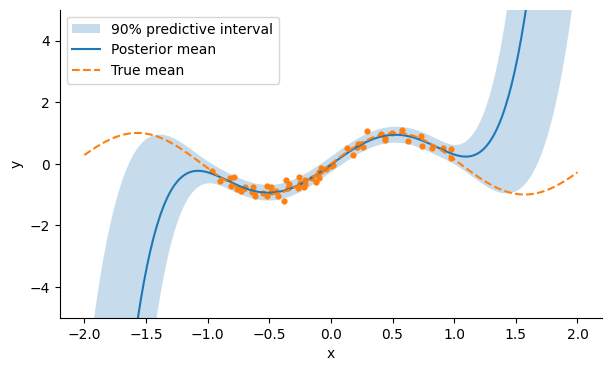

In [3]:
grid = np.linspace(-2, 2, 300)
mean, total_sd = posterior.predict(basis(grid))
_, parameter_sd = posterior.predict(basis(grid), include_noise=False)
np.testing.assert_allclose(total_sd**2-parameter_sd**2, .15**2)
plt.fill_between(grid, mean-1.645*total_sd, mean+1.645*total_sd, alpha=.25, label='90% predictive interval')
plt.plot(grid, mean, label='Posterior mean')
plt.plot(grid, np.sin(3*grid), '--', label='True mean')
plt.scatter(x, y, s=12)
plt.ylim(-5, 5); plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

## Data reduce posterior parameter uncertainty
Compare the same prior with ten versus sixty observations. In this conjugate
model extra data can only reduce the covariance in the positive-semidefinite order.

In [4]:
small = BayesianLinearRegression(1, .15**2).fit(basis(x[:10]), y[:10])
_, small_sd = small.predict(basis(grid), include_noise=False)
assert np.all(parameter_sd <= small_sd + 1e-9)
print(pd.Series(evidence('probabilistic')['posterior']))

in_range_sd         0.161319
extrapolation_sd    8.038815
dtype: float64


## Exercise and worked answer
Would doubling every basis value while keeping the coefficient prior unchanged
preserve the prior over functions? No. The prior function variance is
$\tau^2\phi(x)\phi(x)^T$, so doubling the basis multiplies it by four.
Posterior confidence also depends on the feature family: polynomial uncertainty
does not account for every possible nonpolynomial alternative.